# TP3

En este trabajo práctico buscamos el logo de Coca-Cola en un conjunto de imágenes a partir de un único template. Las imágenes son muy distintas entre sí: el logo aparece en distintos tamaños, con otros colores y a veces sobre superficies curvas. En esta entrega resolvemos el primer punto, que pide una sola detección por imagen y sin falsos positivos.

# Autores
 - Celeste Corominas
 - Christian Yanez
 - Julián Fierens
## Cohorte 27CoCEIA

In [1]:
%matplotlib inline

import os
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# Fijamos la semilla de OpenCV para que FLANN y RANSAC den siempre el mismo resultado.
cv.setRNGSeed(0)

## Punto 1: una detección por imagen

Para encontrar el logo usamos SIFT. La idea general es la siguiente:

- SIFT busca puntos característicos en el template y en la imagen (esquinas, curvas, zonas con mucho contraste) y describe cada uno con un vector de 128 valores. Ese descriptor no cambia si el objeto aparece más grande, más chico o rotado.
- FLANN con kd-tree compara los descriptores y encuentra rápido, para cada punto del template, los dos puntos más parecidos de la imagen.
- El test de Lowe descarta los matches dudosos: nos quedamos con un match solo si el mejor candidato es claramente mejor que el segundo (distancia menor a 0,75 veces la del segundo).
- RANSAC toma los matches que quedaron y busca la transformación que explica la mayor cantidad de ellos. Los matches que coinciden con esa transformación son los inliers; el resto se descarta.

Con la transformación llevamos las esquinas del template a la imagen y así obtenemos la caja del logo.

### El template

El template es el logo rojo sobre un fondo blanco amplio. Primero lo recortamos al contenido, quedándonos con los píxeles más oscuros que 200 en escala de grises, para que el fondo blanco no agregue puntos sin información y la caja final se ajuste al logo.

Template original: (175, 400)  recortado: (115, 373)


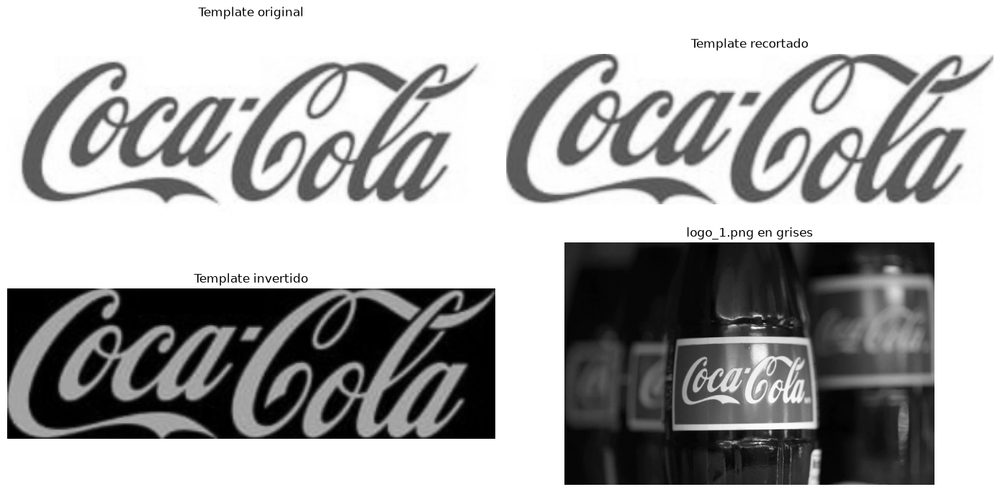

In [2]:
template = cv.imread('template/pattern.png')
template_gris = cv.cvtColor(template, cv.COLOR_BGR2GRAY)

# Recortamos el template al rectángulo que contiene al logo.
ys, xs = np.where(template_gris < 200)
template_rec = template_gris[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
template_inv = 255 - template_rec
print('Template original:', template_gris.shape, ' recortado:', template_rec.shape)

ejemplo = cv.cvtColor(cv.imread('images/logo_1.png'), cv.COLOR_BGR2GRAY)

plt.figure(figsize=(14, 7))
titulos = ['Template original', 'Template recortado', 'Template invertido', 'logo_1.png en grises']
imagenes = [template_gris, template_rec, template_inv, ejemplo]
for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(imagenes[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titulos[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

En escala de grises el template es un logo gris oscuro sobre fondo blanco. En casi todas las imágenes pasa lo contrario: el logo es blanco sobre un fondo rojo, que en grises queda gris oscuro, como se ve en `logo_1.png`. Esto es un problema para SIFT, porque su descriptor se arma con la dirección de los gradientes, y al invertir claro y oscuro todos los gradientes apuntan al revés. En las pruebas, con el template tal cual SIFT casi no encontraba matches en esas imágenes.

Como solución propia probamos las dos versiones del template, la normal y la invertida (`255 - template`), y nos quedamos con la que da más inliers. La única imagen que conserva la polaridad del template es `coca_retro_1.png`, donde el logo es negro sobre blanco.

### Detección con SIFT

La función `detectar_sift` sigue el código de la Clase 5 (FLANN + homografía), con un cambio: en lugar de una homografía estimamos la transformación con `cv.estimateAffinePartial2D`. Esta función solo permite escala, rotación y traslación, así que necesita menos matches que una homografía (2 en lugar de 4) y la caja resultante sigue siendo un rectángulo sin deformar. Fue una elección nuestra: en las pruebas, la homografía daba cajas parecidas en las imágenes con muchos matches, pero con pocos matches (como en `coca_multi.png`) devolvía un cuadrilátero sin sentido.

Como confianza usamos la proporción de inliers sobre los matches que pasaron el test de Lowe. Un valor cercano a 1 indica que casi todos los matches coinciden con la misma transformación.

In [3]:
sift = cv.SIFT_create()
flann = cv.FlannBasedMatcher(dict(algorithm=1, trees=5), dict(checks=50))  # algorithm=1 es kd-tree


def detectar_sift(img_gris, template_gris):
    kp_t, des_t = sift.detectAndCompute(template_gris, None)
    kp_i, des_i = sift.detectAndCompute(img_gris, None)
    if des_t is None or des_i is None or len(kp_i) < 2:
        return None

    # Test de Lowe: el mejor match tiene que ser bastante mejor que el segundo.
    buenos = [m for m, n in flann.knnMatch(des_t, des_i, k=2) if m.distance < 0.75 * n.distance]
    if len(buenos) < 3:
        return None

    src = np.float32([kp_t[m.queryIdx].pt for m in buenos]).reshape(-1, 1, 2)
    dst = np.float32([kp_i[m.trainIdx].pt for m in buenos]).reshape(-1, 1, 2)
    M, mascara = cv.estimateAffinePartial2D(src, dst, method=cv.RANSAC, ransacReprojThreshold=5.0)
    if M is None:
        return None

    # Llevamos las 4 esquinas del template a la imagen y tomamos el rectángulo que las contiene.
    h, w = template_gris.shape
    esquinas = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
    caja = cv.boundingRect(cv.transform(esquinas, M))

    inliers = int(mascara.sum())
    return {'caja': caja, 'inliers': inliers, 'confianza': inliers / len(buenos),
            'escala': np.hypot(M[0, 0], M[1, 0]), 'angulo': np.degrees(np.arctan2(M[1, 0], M[0, 0])),
            'kp_t': kp_t, 'kp_i': kp_i, 'buenos': buenos, 'mascara': mascara}

### Respaldo con template matching

Si SIFT no encuentra suficientes puntos, usamos template matching. Como no sabemos de qué tamaño aparece el logo, lo probamos en muchas escalas: achicamos o agrandamos el template desde 50 px de ancho hasta el ancho de la imagen (con un tope de 1300 px), de a 5 px, y nos quedamos con la posición y el tamaño de mayor correlación. Usamos `TM_CCOEFF_NORMED`, que da un valor entre -1 y 1, y ese valor es la confianza.

In [4]:
def detectar_template(img_gris, template_gris):
    alto_t, ancho_t = template_gris.shape
    mejor = None
    for ancho in range(50, min(img_gris.shape[1], 1300) + 1, 5):
        alto = int(alto_t * ancho / ancho_t)
        if alto > img_gris.shape[0]:
            break
        t = cv.resize(template_gris, (ancho, alto), interpolation=cv.INTER_AREA)
        res = cv.matchTemplate(img_gris, t, cv.TM_CCOEFF_NORMED)
        _, max_val, _, max_loc = cv.minMaxLoc(res)
        if mejor is None or max_val > mejor['confianza']:
            mejor = {'caja': (max_loc[0], max_loc[1], ancho, alto), 'confianza': max_val}
    return mejor

### Una detección por imagen

La función `detectar_logo` junta todo. Primero prueba SIFT con el template normal y con el invertido y se queda con el que tiene más inliers. Esa detección se acepta solo si tiene sentido geométrico:

- al menos 6 inliers;
- una escala entre 0,1 y 5 respecto del template recortado;
- un ángulo menor a 30° (en estas imágenes el logo está casi horizontal);
- el centro de la caja dentro de la imagen.

Si SIFT no pasa estos controles, se prueba template matching con las dos polaridades y se acepta el resultado si la correlación es de al menos 0,5. Si tampoco pasa, la función devuelve que no hay detección. Preferimos eso antes que marcar algo que no es el logo.

In [5]:
def detectar_logo(img_bgr, template_gris):
    # Fijamos la semilla en cada llamada para que RANSAC dé el mismo resultado
    # aunque la celda se ejecute sola o en otro orden.
    cv.setRNGSeed(0)
    img_gris = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)
    alto, ancho = img_gris.shape
    polaridades = {'normal': template_gris, 'invertido': 255 - template_gris}

    # 1) SIFT con las dos polaridades, nos quedamos con la de más inliers.
    mejor, pol_mejor = None, None
    for pol, t in polaridades.items():
        r = detectar_sift(img_gris, t)
        if r is not None and (mejor is None or r['inliers'] > mejor['inliers']):
            mejor, pol_mejor = r, pol

    if mejor is not None:
        x, y, w, h = mejor['caja']
        cx, cy = x + w / 2, y + h / 2
        if (mejor['inliers'] >= 6 and 0.1 <= mejor['escala'] <= 5 and abs(mejor['angulo']) < 30
                and 0 <= cx < ancho and 0 <= cy < alto):
            return {'metodo': 'SIFT', 'polaridad': pol_mejor, 'caja': mejor['caja'],
                    'confianza': mejor['confianza'], 'detalle': mejor}

    # 2) Respaldo: template matching multiescala con las dos polaridades.
    mejor, pol_mejor = None, None
    for pol, t in polaridades.items():
        r = detectar_template(img_gris, t)
        if r is not None and (mejor is None or r['confianza'] > mejor['confianza']):
            mejor, pol_mejor = r, pol

    if mejor is not None and mejor['confianza'] >= 0.5:
        return {'metodo': 'Template', 'polaridad': pol_mejor, 'caja': mejor['caja'],
                'confianza': mejor['confianza'], 'detalle': mejor}

    return None

### Resultados

Aplicamos `detectar_logo` a las siete imágenes, dibujamos la caja en verde con el método y la confianza, y mostramos todo junto. El texto lleva un fondo negro para que se lea sobre cualquier color, y el grosor de la línea y el tamaño de la letra dependen del tamaño de cada imagen.

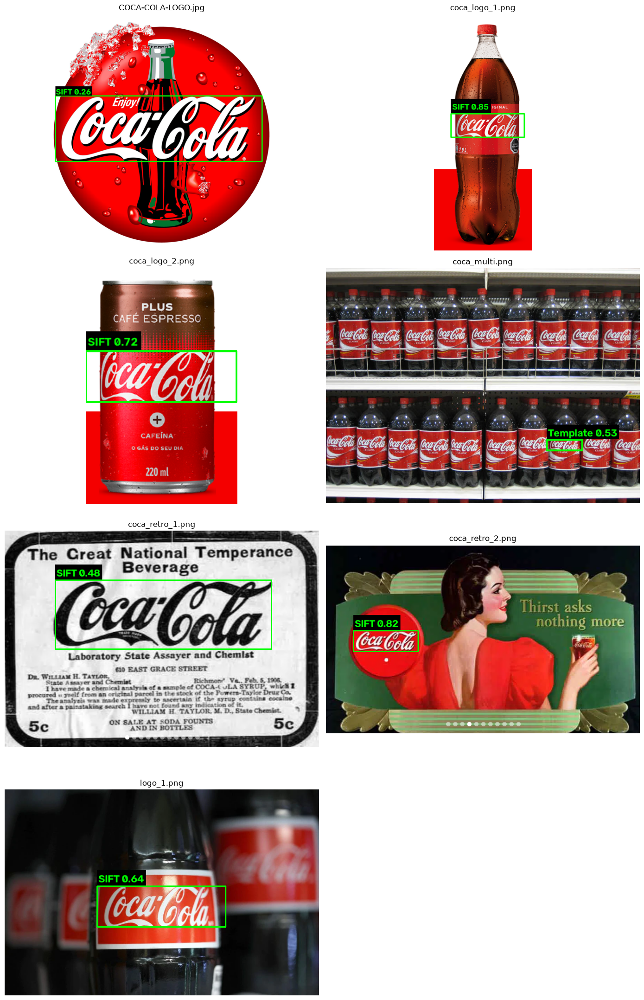

In [6]:
nombres = sorted(os.listdir('images'))
resultados = {}

plt.figure(figsize=(14, 22))
for i, nombre in enumerate(nombres):
    img = cv.imread('images/' + nombre)
    det = detectar_logo(img, template_rec)
    resultados[nombre] = det
    salida = img.copy()

    if det is not None:
        # Recortamos la caja a los bordes de la imagen.
        x, y, w, h = det['caja']
        x1, y1 = max(x, 0), max(y, 0)
        x2, y2 = min(x + w, img.shape[1] - 1), min(y + h, img.shape[0] - 1)
        det['caja_dibujada'] = (x1, y1, x2 - x1, y2 - y1)

        grosor = max(2, img.shape[1] // 250)
        letra = max(0.6, img.shape[1] / 900)
        texto = f"{det['metodo']} {det['confianza']:.2f}"
        cv.rectangle(salida, (x1, y1), (x2, y2), (0, 255, 0), grosor)
        # Fondo negro detrás del texto para que se lea sobre cualquier color.
        (tw, th), _ = cv.getTextSize(texto, cv.FONT_HERSHEY_SIMPLEX, letra, grosor)
        ty = max(y1 - 8, th + 8)
        cv.rectangle(salida, (x1, ty - th - 6), (x1 + tw + 6, ty + 6), (0, 0, 0), -1)
        cv.putText(salida, texto, (x1 + 3, ty), cv.FONT_HERSHEY_SIMPLEX, letra, (0, 255, 0), grosor)

    plt.subplot(4, 2, i + 1)
    plt.imshow(cv.cvtColor(salida, cv.COLOR_BGR2RGB))
    plt.title(nombre)
    plt.axis('off')
plt.tight_layout()
plt.show()

In [7]:
print(f"{'Imagen':<20} {'Método':<9} {'Polaridad':<10} {'Inliers/Corr.':>13} {'Confianza':>10}   Caja (x, y, ancho, alto)")
for nombre, det in resultados.items():
    if det is None:
        print(f'{nombre:<20} sin detección')
        continue
    if det['metodo'] == 'SIFT':
        valor = str(det['detalle']['inliers'])
    else:
        valor = f"{det['confianza']:.3f}"
    print(f"{nombre:<20} {det['metodo']:<9} {det['polaridad']:<10} {valor:>13} {det['confianza']:>10.2f}   {det['caja_dibujada']}")

Imagen               Método    Polaridad  Inliers/Corr.  Confianza   Caja (x, y, ancho, alto)
COCA-COLA-LOGO.jpg   SIFT      invertido              6       0.26   (70, 480, 1214, 385)
coca_logo_1.png      SIFT      invertido             29       0.85   (36, 210, 155, 50)
coca_logo_2.png      SIFT      invertido             23       0.72   (0, 128, 231, 78)
coca_multi.png       Template  invertido          0.531       0.53   (562, 436, 90, 27)
coca_retro_1.png     SIFT      normal                13       0.48   (115, 112, 492, 157)
coca_retro_2.png     SIFT      invertido             18       0.82   (63, 195, 147, 47)
logo_1.png           SIFT      invertido             16       0.64   (202, 211, 281, 89)


### Cómo matchea SIFT

Para ver qué está haciendo SIFT dibujamos los inliers entre el template invertido y `logo_1.png`.

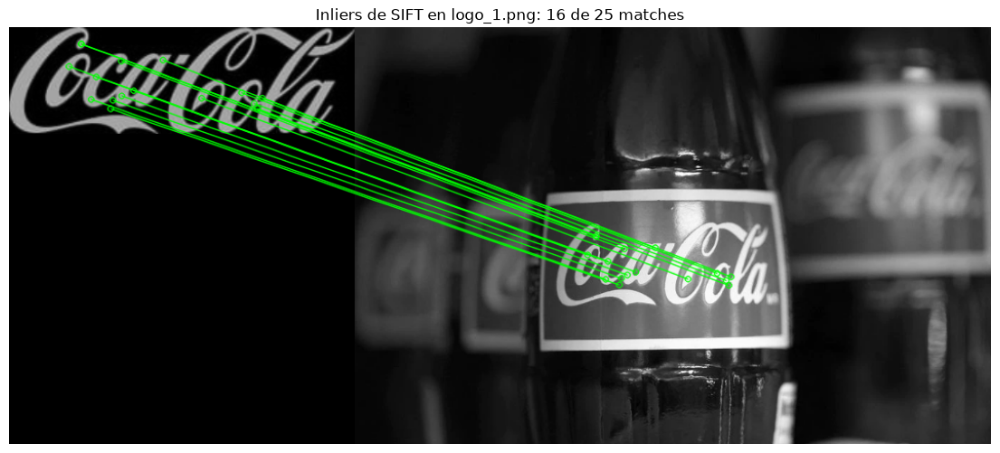

In [8]:
img = cv.imread('images/logo_1.png')
det = resultados['logo_1.png']['detalle']
plantilla = template_inv if resultados['logo_1.png']['polaridad'] == 'invertido' else template_rec

vista = cv.drawMatches(plantilla, det['kp_t'], cv.cvtColor(img, cv.COLOR_BGR2GRAY), det['kp_i'], det['buenos'], None,
                       matchColor=(0, 255, 0), matchesMask=det['mascara'].ravel().tolist(), flags=2)
plt.figure(figsize=(14, 6))
plt.imshow(vista)
plt.title(f"Inliers de SIFT en logo_1.png: {det['inliers']} de {len(det['buenos'])} matches")
plt.axis('off')
plt.show()

### Análisis

Se obtuvo una sola caja en cada una de las siete imágenes y todas caen sobre un logo de Coca-Cola. No hubo falsos positivos.

SIFT resolvió seis de las siete imágenes. En cinco de ellas la detección salió con el template invertido, y solo en `coca_retro_1.png`, donde el logo es negro sobre papel blanco, funcionó el template tal cual. Sin la inversión, SIFT no habría encontrado el logo en la mayoría de las imágenes. En `logo_1.png` se ve bien cómo trabaja: 16 de los 25 matches son inliers y todos unen trazos del template con las letras de la botella del frente, no con las botellas desenfocadas del fondo.

La confianza no significa lo mismo en los dos métodos. En SIFT es la fracción de matches que coinciden con la transformación encontrada, y en template matching es el valor de correlación normalizada. Por eso no se puede comparar un 0,85 de SIFT con un 0,53 de template matching. Dentro de cada método sí sirve como referencia: con SIFT, las imágenes donde el logo se ve plano y nítido (`coca_logo_1.png` y `coca_retro_2.png`) dan los valores más altos.

## Punto 2: múltiples detecciones en coca_multi.png

En esta imagen hay una góndola llena de botellas de Coca-Cola, así que el logo aparece muchas veces. SIFT no sirve acá: cada logo mide unos 85 px de ancho y, como vimos en el punto 1, a ese tamaño casi no quedan puntos característicos. Por eso usamos template matching, que compara el template con cada posición de la imagen.

Como no sabemos de qué tamaño aparece el logo, probamos el template en varios tamaños: lo achicamos de 50 px a 400 px de ancho (manteniendo la proporción) y en cada tamaño corremos el matching sobre toda la imagen.

La diferencia con el punto 1 es que no nos quedamos con el máximo de correlación, sino con todas las posiciones que superan un umbral. El problema es que un mismo logo genera muchas cajas superpuestas, en posiciones vecinas y en escalas parecidas. Para quedarnos con una sola caja por logo usamos NMS (supresión de no máximos), que se menciona en las slides de la Clase 4: se ordenan las detecciones por puntaje, se conserva la de mayor puntaje y se descartan las que se superponen con ella en más de un 30 % (medido por IoU, intersección sobre unión).


In [9]:
def detectar_multiples(img_gris, template_gris, umbral, anchos=range(50, 401, 5), iou=0.3, bordes=False):
    alto_t, ancho_t = template_gris.shape
    img = cv.Canny(img_gris, 100, 200) if bordes else img_gris

    cajas, puntajes = [], []
    for ancho in anchos:
        alto = int(alto_t * ancho / ancho_t)
        # Si el template queda más alto o más ancho que la imagen, no entra.
        if alto < 1 or alto > img.shape[0] or ancho > img.shape[1]:
            continue
        t = cv.resize(template_gris, (ancho, alto), interpolation=cv.INTER_AREA)
        if bordes:
            t = cv.Canny(t, 100, 200)
        res = cv.matchTemplate(img, t, cv.TM_CCOEFF_NORMED)
        # Tomamos todas las posiciones que superan el umbral, no solo el máximo.
        ys, xs = np.where(res >= umbral)
        for x, y in zip(xs, ys):
            cajas.append([x, y, ancho, alto])
            puntajes.append(float(res[y, x]))

    if not cajas:
        return []

    # NMS: conserva la mejor caja y descarta las que se superponen más de iou.
    indices = cv.dnn.NMSBoxes(cajas, puntajes, umbral, iou)
    detecciones = [{'caja': tuple(cajas[i]), 'confianza': puntajes[i]} for i in indices.flatten()]
    detecciones.sort(key=lambda d: d['confianza'], reverse=True)
    return detecciones


In [10]:
def dibujar_detecciones(img_bgr, detecciones):
    salida = img_bgr.copy()
    alto, ancho = salida.shape[:2]
    grosor = max(2, ancho // 250)
    letra = max(0.6, ancho / 900)
    for det in detecciones:
        x, y, w, h = det['caja']
        x1, y1 = max(x, 0), max(y, 0)
        x2, y2 = min(x + w, ancho - 1), min(y + h, alto - 1)
        cv.rectangle(salida, (x1, y1), (x2, y2), (0, 255, 0), grosor)
        # Confianza con dos decimales sobre un fondo negro, como en el punto 1.
        # Si la detección tiene método, ponemos su inicial delante (punto 3): T = Template, S = SIFT.
        texto = f"{det['metodo'][0]} {det['confianza']:.2f}" if 'metodo' in det else f"{det['confianza']:.2f}"
        (tw, th), _ = cv.getTextSize(texto, cv.FONT_HERSHEY_SIMPLEX, letra, grosor)
        ty = max(y1 - 8, th + 8)
        cv.rectangle(salida, (x1, ty - th - 6), (x1 + tw + 6, ty + 6), (0, 0, 0), -1)
        cv.putText(salida, texto, (x1 + 3, ty), cv.FONT_HERSHEY_SIMPLEX, letra, (0, 255, 0), grosor)
    return salida


### Validación del umbral

El umbral decide cuántas posiciones se toman como "logo". Elegirlo es un equilibrio, así que lo validamos corriendo el detector con varios valores y contando cuántas cajas devuelve cada uno.


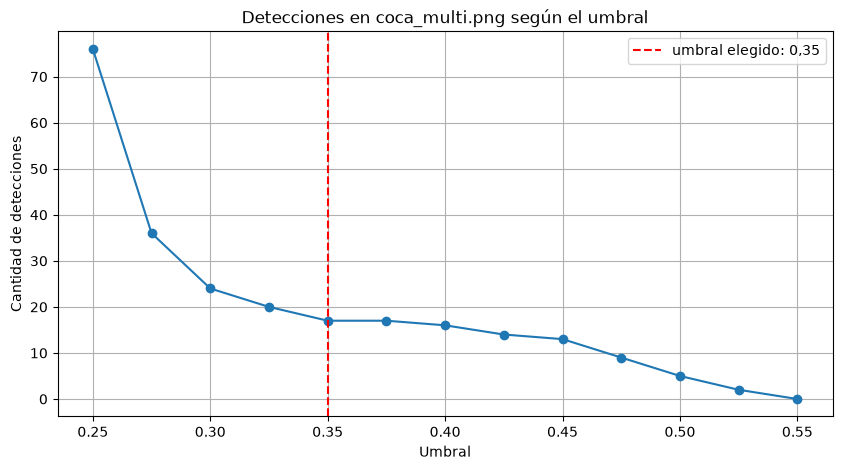

In [11]:
img_multi = cv.imread('images/coca_multi.png')
img_multi_gris = cv.cvtColor(img_multi, cv.COLOR_BGR2GRAY)

umbrales = np.arange(0.25, 0.551, 0.025)
cantidades = [len(detectar_multiples(img_multi_gris, template_inv, u)) for u in umbrales]

plt.figure(figsize=(10, 5))
plt.plot(umbrales, cantidades, marker='o')
plt.axvline(0.35, color='red', linestyle='--', label='umbral elegido: 0,35')
plt.xlabel('Umbral')
plt.ylabel('Cantidad de detecciones')
plt.title('Detecciones en coca_multi.png según el umbral')
plt.legend()
plt.grid(True)
plt.show()


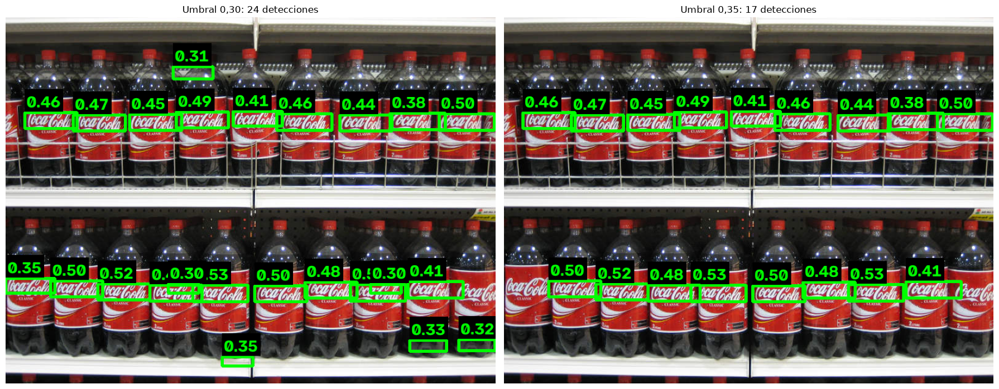

In [12]:
dets_030 = detectar_multiples(img_multi_gris, template_inv, 0.30)
dets_035 = detectar_multiples(img_multi_gris, template_inv, 0.35)

fig, ejes = plt.subplots(1, 2, figsize=(18, 7))
ejes[0].imshow(cv.cvtColor(dibujar_detecciones(img_multi, dets_030), cv.COLOR_BGR2RGB))
ejes[0].set_title(f'Umbral 0,30: {len(dets_030)} detecciones')
ejes[0].axis('off')
ejes[1].imshow(cv.cvtColor(dibujar_detecciones(img_multi, dets_035), cv.COLOR_BGR2RGB))
ejes[1].set_title(f'Umbral 0,35: {len(dets_035)} detecciones')
ejes[1].axis('off')
plt.tight_layout()
plt.show()


Con umbrales bajos aparecen cajas sobre zonas que no son logos: con 0,25 hay más de 70 y la mayoría no sirven. Con umbrales altos se pierden logos: con 0,50 quedan solo 5. El punto medio es 0,35, que es el valor más bajo que, revisado visualmente, no tiene falsos positivos.

En la figura de la derecha (0,35) todas las cajas caen sobre un logo. En la de la izquierda (0,30) aparecen 4 cajas de más por arriba y por abajo de la góndola, en zonas sin logos: son falsos positivos.


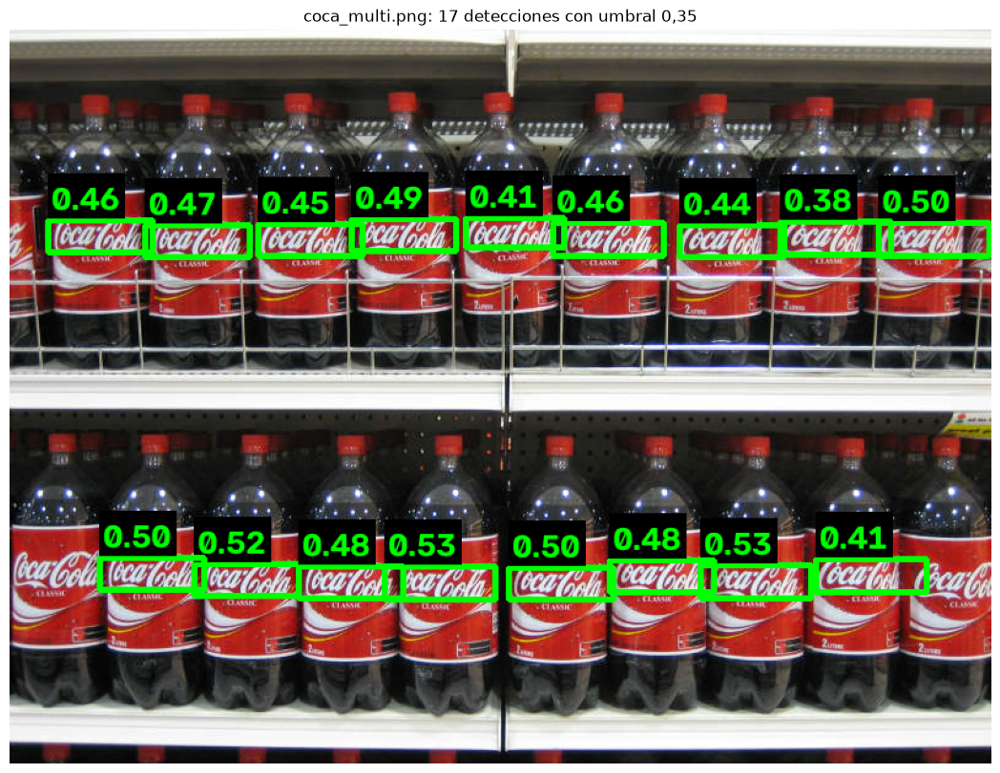

Cantidad de detecciones: 17
Confianzas entre 0.378 y 0.531


In [13]:
detecciones = detectar_multiples(img_multi_gris, template_inv, 0.35)
salida = dibujar_detecciones(img_multi, detecciones)

plt.figure(figsize=(14, 10))
plt.imshow(cv.cvtColor(salida, cv.COLOR_BGR2RGB))
plt.title(f'coca_multi.png: {len(detecciones)} detecciones con umbral 0,35')
plt.axis('off')
plt.show()

confianzas = [d['confianza'] for d in detecciones]
print(f'Cantidad de detecciones: {len(detecciones)}')
print(f'Confianzas entre {min(confianzas):.3f} y {max(confianzas):.3f}')


### Comparación con bordes de Canny

Probamos el template matching sobre los bordes en lugar de la imagen en grises. La idea es correlacionar solo los contornos, que no dependen del color. Probamos aplicando `cv.Canny` con umbrales 100 y 200 a la imagen y a cada template escalado, usando la misma función con `bordes=True`.


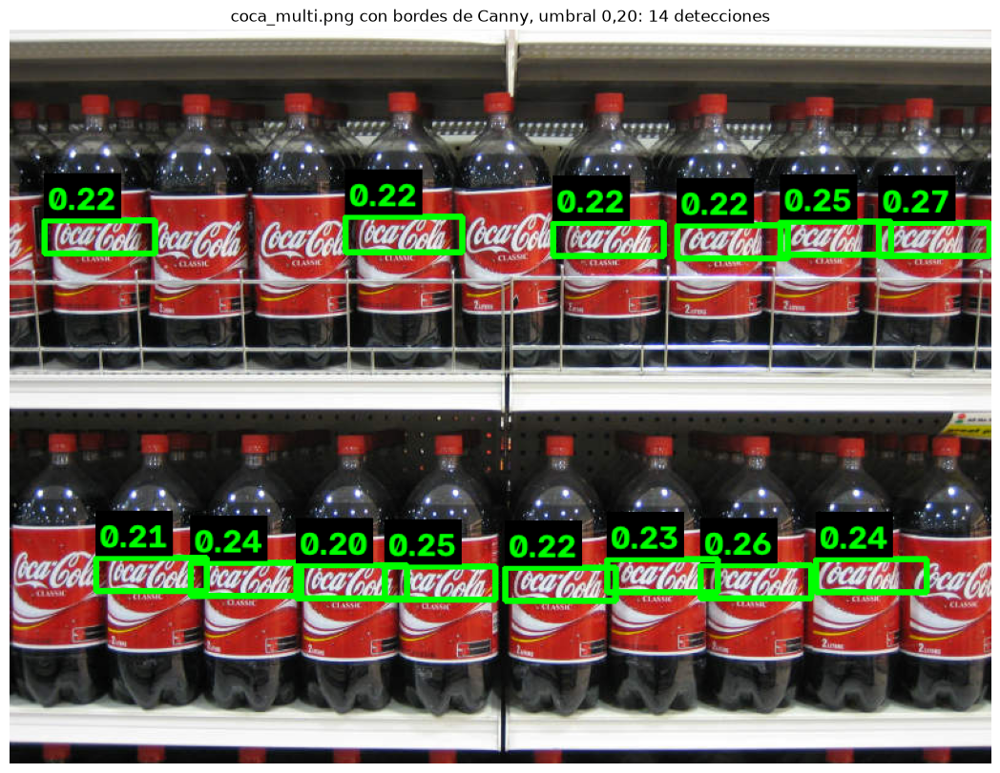

In [14]:
dets_bordes = detectar_multiples(img_multi_gris, template_inv, 0.20, anchos=range(60, 121, 5), bordes=True)

plt.figure(figsize=(14, 10))
plt.imshow(cv.cvtColor(dibujar_detecciones(img_multi, dets_bordes), cv.COLOR_BGR2RGB))
plt.title(f'coca_multi.png con bordes de Canny, umbral 0,20: {len(dets_bordes)} detecciones')
plt.axis('off')
plt.show()


Con bordes se pierde la información de intensidad, que acá ayuda porque el logo es blanco sobre un fondo rojo (que en grises queda oscuro y el matching lo aprovecha). Por eso se detectan menos logos (14 contra 17) y el umbral es más delicado: con 0,15 ya aparecían falsos positivos y con 0,25 solo quedaban 3. Nos quedamos con la imagen en grises.


### Análisis del punto 2

Con umbral 0,35 detectamos 17 logos y no hay falsos positivos: las 9 cajas del estante de arriba y las 8 del de abajo caen todas sobre un logo. En la imagen hay unos 18 logos completos y otros 3 o 4 cortados por los bordes, así que se detectan casi todos los completos. Los que faltan son los cortados por los bordes y el de la botella de abajo a la izquierda: ese está completo, pero su correlación es 0,349 y queda justo por debajo del umbral.


## Punto 3: un algoritmo para todas las imágenes

Ahora juntamos todo en un único algoritmo que corre igual sobre las siete imágenes. Respecto del punto 2 cambian cuatro cosas:

- **Polaridad automática.** En cada imagen probamos el template normal y el invertido, y usamos el que da la correlación máxima más alta. Así no hay que decidir a mano si el logo es claro sobre oscuro o al revés.
- **Umbral adaptativo.** Usamos `max(0,35; 0,7 × máximo)`. El 0,35 fijo del punto 2 sirve cuando los logos se parecen poco al template, como en la góndola. Pero cuando el logo se ve muy nítido (máximos de 0,65–0,69), algunas zonas que no son logos también pasan 0,35. Pedir además que la caja tenga al menos el 70 % del mejor puntaje de esa imagen las elimina. Es una elección propia.
- **Rango de escalas.** Achicamos el template de 50 px hasta `min(ancho, 1300)` px, como en el punto 1, porque el logo grande de `COCA-COLA-LOGO.jpg` mide casi 1200 px.
- **SIFT como complemento.** Template matching no encuentra la lata (`coca_logo_2.png`) porque el logo está curvado, y SIFT sí, como en el punto 1. Agregamos la detección SIFT solo si no se superpone con ninguna caja ya encontrada.

En las figuras, cada caja lleva la inicial del método que la encontró (T para template matching, S para SIFT) y su confianza.


In [15]:
def iou(a, b):
    # Intersección sobre unión entre dos cajas (x, y, ancho, alto).
    ax, ay, aw, ah = a
    bx, by, bw, bh = b
    x1, y1 = max(ax, bx), max(ay, by)
    x2, y2 = min(ax + aw, bx + bw), min(ay + ah, by + bh)
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    union = aw * ah + bw * bh - inter
    return inter / union if union > 0 else 0.0


In [16]:
def detectar_general(img_bgr):
    img_gris = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)
    # El logo puede aparecer muy grande (hasta ~1200 px en COCA-COLA-LOGO.jpg).
    anchos = range(50, min(img_gris.shape[1], 1300) + 1, 5)

    # Polaridad: nos quedamos con la que da la correlación máxima más alta.
    polaridades = {'normal': template_rec, 'invertido': template_inv}
    mejor_pol, maximo = None, -1
    for pol, t in polaridades.items():
        r = detectar_template(img_gris, t)
        if r is not None and r['confianza'] > maximo:
            maximo, mejor_pol = r['confianza'], pol
    t_elegido = polaridades[mejor_pol]

    # Umbral adaptativo: nunca menos que 0,35, y al menos el 70 % del mejor
    # puntaje de la imagen, para descartar zonas que se parecen al logo.
    umbral = max(0.35, 0.7 * maximo)
    detecciones = detectar_multiples(img_gris, t_elegido, umbral, anchos)
    for d in detecciones:
        d['metodo'] = 'Template'

    # SIFT como complemento: solo si no se superpone con lo ya detectado.
    det = detectar_logo(img_bgr, template_rec)
    if det is not None and det['metodo'] == 'SIFT':
        if all(iou(det['caja'], d['caja']) < 0.3 for d in detecciones):
            detecciones.append(det)

    return detecciones, mejor_pol, maximo, umbral


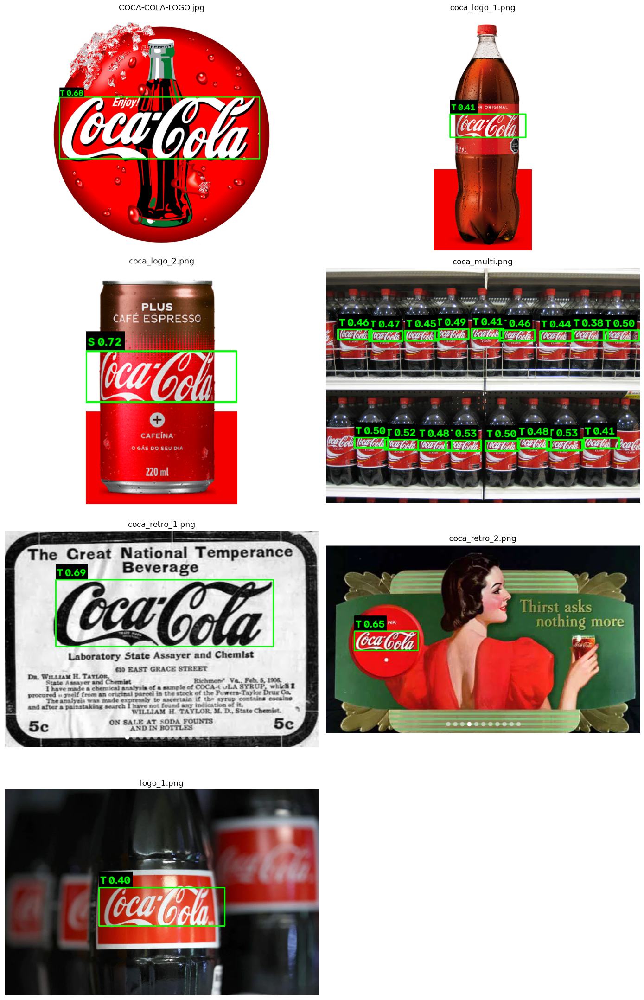

In [17]:
resultados3 = {}
plt.figure(figsize=(14, 22))
for i, nombre in enumerate(sorted(os.listdir('images'))):
    img = cv.imread('images/' + nombre)
    dets, pol, maximo, umbral = detectar_general(img)
    resultados3[nombre] = (dets, pol, maximo, umbral)

    salida = dibujar_detecciones(img, dets)
    plt.subplot(4, 2, i + 1)
    plt.imshow(cv.cvtColor(salida, cv.COLOR_BGR2RGB))
    plt.title(nombre)
    plt.axis('off')
plt.tight_layout()
plt.show()


In [18]:
print(f"{'Imagen':<20} {'Polaridad':<10} {'Máximo':>7} {'Umbral':>7}   Detecciones")
for nombre, (dets, pol, maximo, umbral) in resultados3.items():
    metodos = '+'.join(sorted(set(d['metodo'] for d in dets)))
    print(f"{nombre:<20} {pol:<10} {maximo:>7.3f} {umbral:>7.3f}   {len(dets)} {metodos}")


Imagen               Polaridad   Máximo  Umbral   Detecciones
COCA-COLA-LOGO.jpg   invertido    0.679   0.475   1 Template
coca_logo_1.png      invertido    0.411   0.350   1 Template
coca_logo_2.png      normal       0.323   0.350   1 SIFT
coca_multi.png       invertido    0.531   0.371   17 Template
coca_retro_1.png     normal       0.691   0.484   1 Template
coca_retro_2.png     invertido    0.649   0.455   1 Template
logo_1.png           invertido    0.396   0.350   1 Template


### Análisis del punto 3

El mismo algoritmo, sin ajustar nada por imagen, encuentra el logo en las siete imágenes: una caja en cada una, salvo en la góndola, donde aparecen las 17 del punto 2. Mirando la figura no hay ninguna caja fuera de un logo ni dos cajas sobre el mismo logo.

El umbral adaptativo hizo falta porque el 0,35 fijo no alcanza cuando el logo se ve muy nítido. En `coca_retro_1.png` el mejor puntaje es 0,691 y, con 0,35, también pasaba una caja falsa de 0,354 en una zona sin logo. Pedir que la caja tenga al menos el 70 % del mejor puntaje (0,7 × 0,691 = 0,484) elimina ese caso.

SIFT hizo falta para la lata: el logo está curvado y template matching no lo encuentra, pero SIFT sí, como en el punto 1. Por eso en la tabla la lata figura con polaridad normal y un máximo de 0,323: son los valores de template matching, que no llegó al umbral. La caja que se ve es la de SIFT, que usó el template invertido. La confianza no se puede comparar entre métodos: en Template es la correlación normalizada (entre −1 y 1) y en SIFT es la fracción de inliers.

Lo que no se detecta: el logo chico del vaso en `coca_retro_2.png` (mide menos de 50 px, y bajar el mínimo agregaba falsos positivos), los logos desenfocados del fondo en `logo_1.png` y los cortados por los bordes en la góndola. Los parámetros (0,35, 0,7 y 50 px) se eligieron mirando estas siete imágenes; con otras habría que revisarlos.
